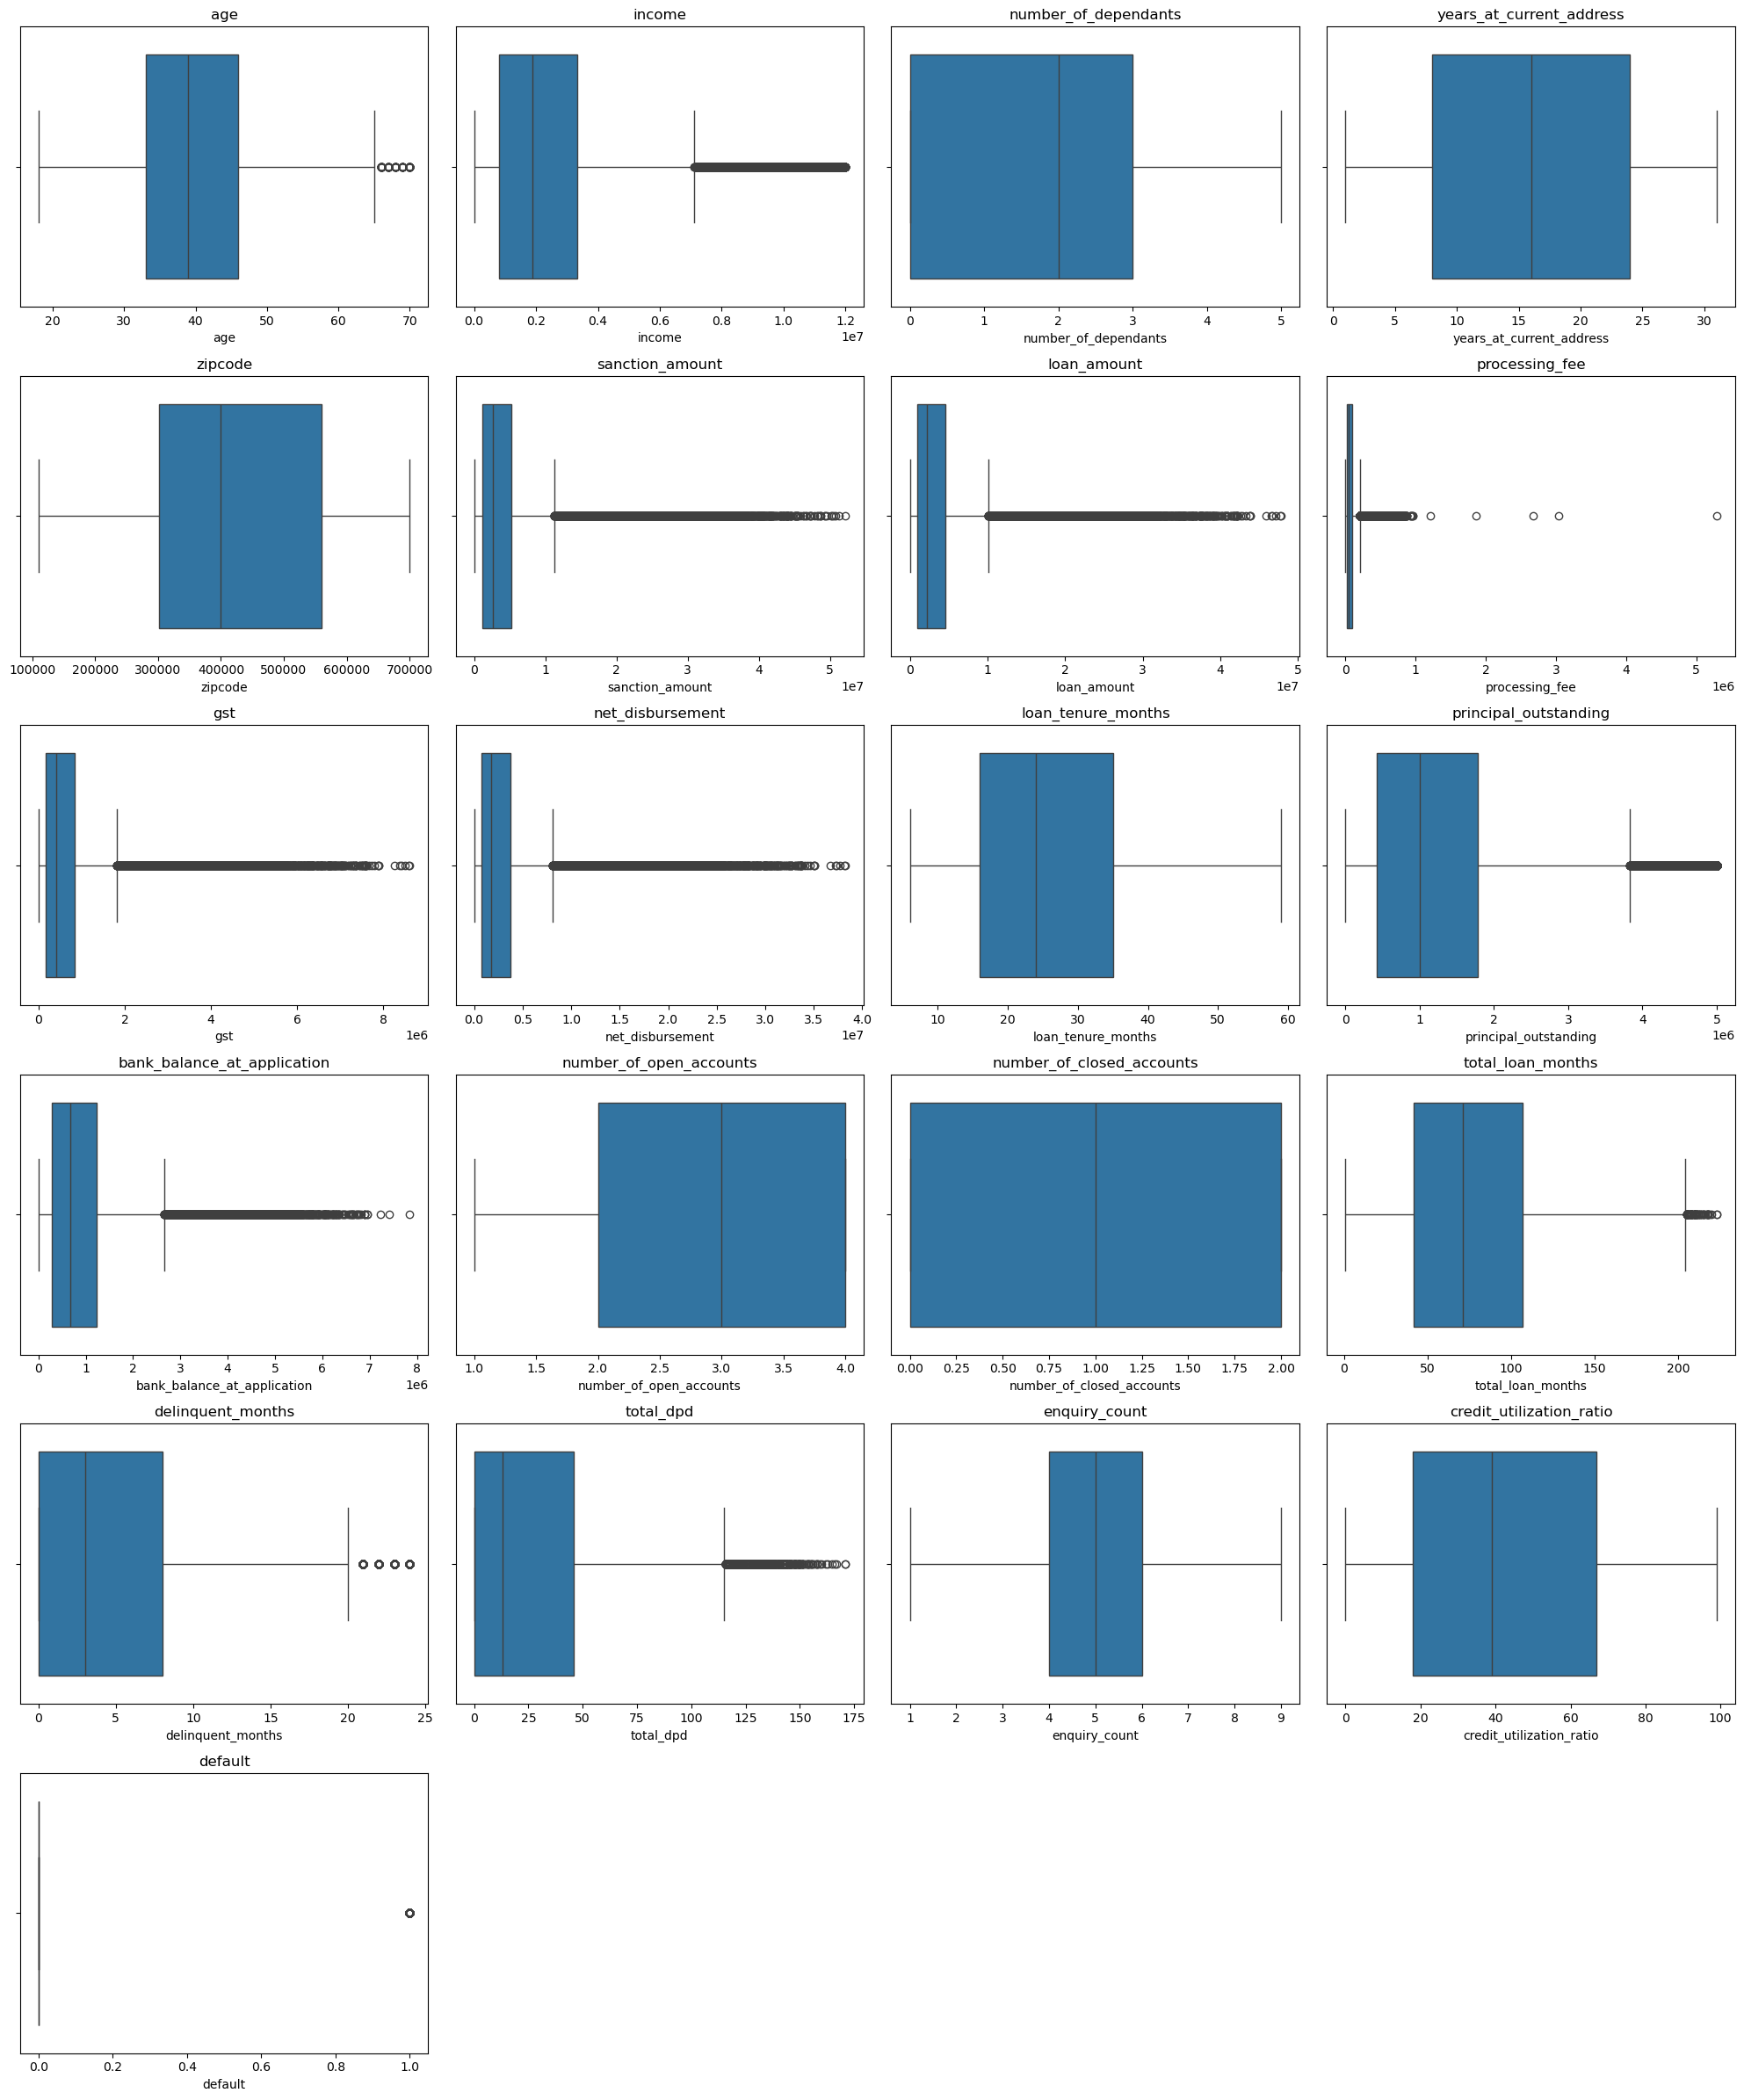

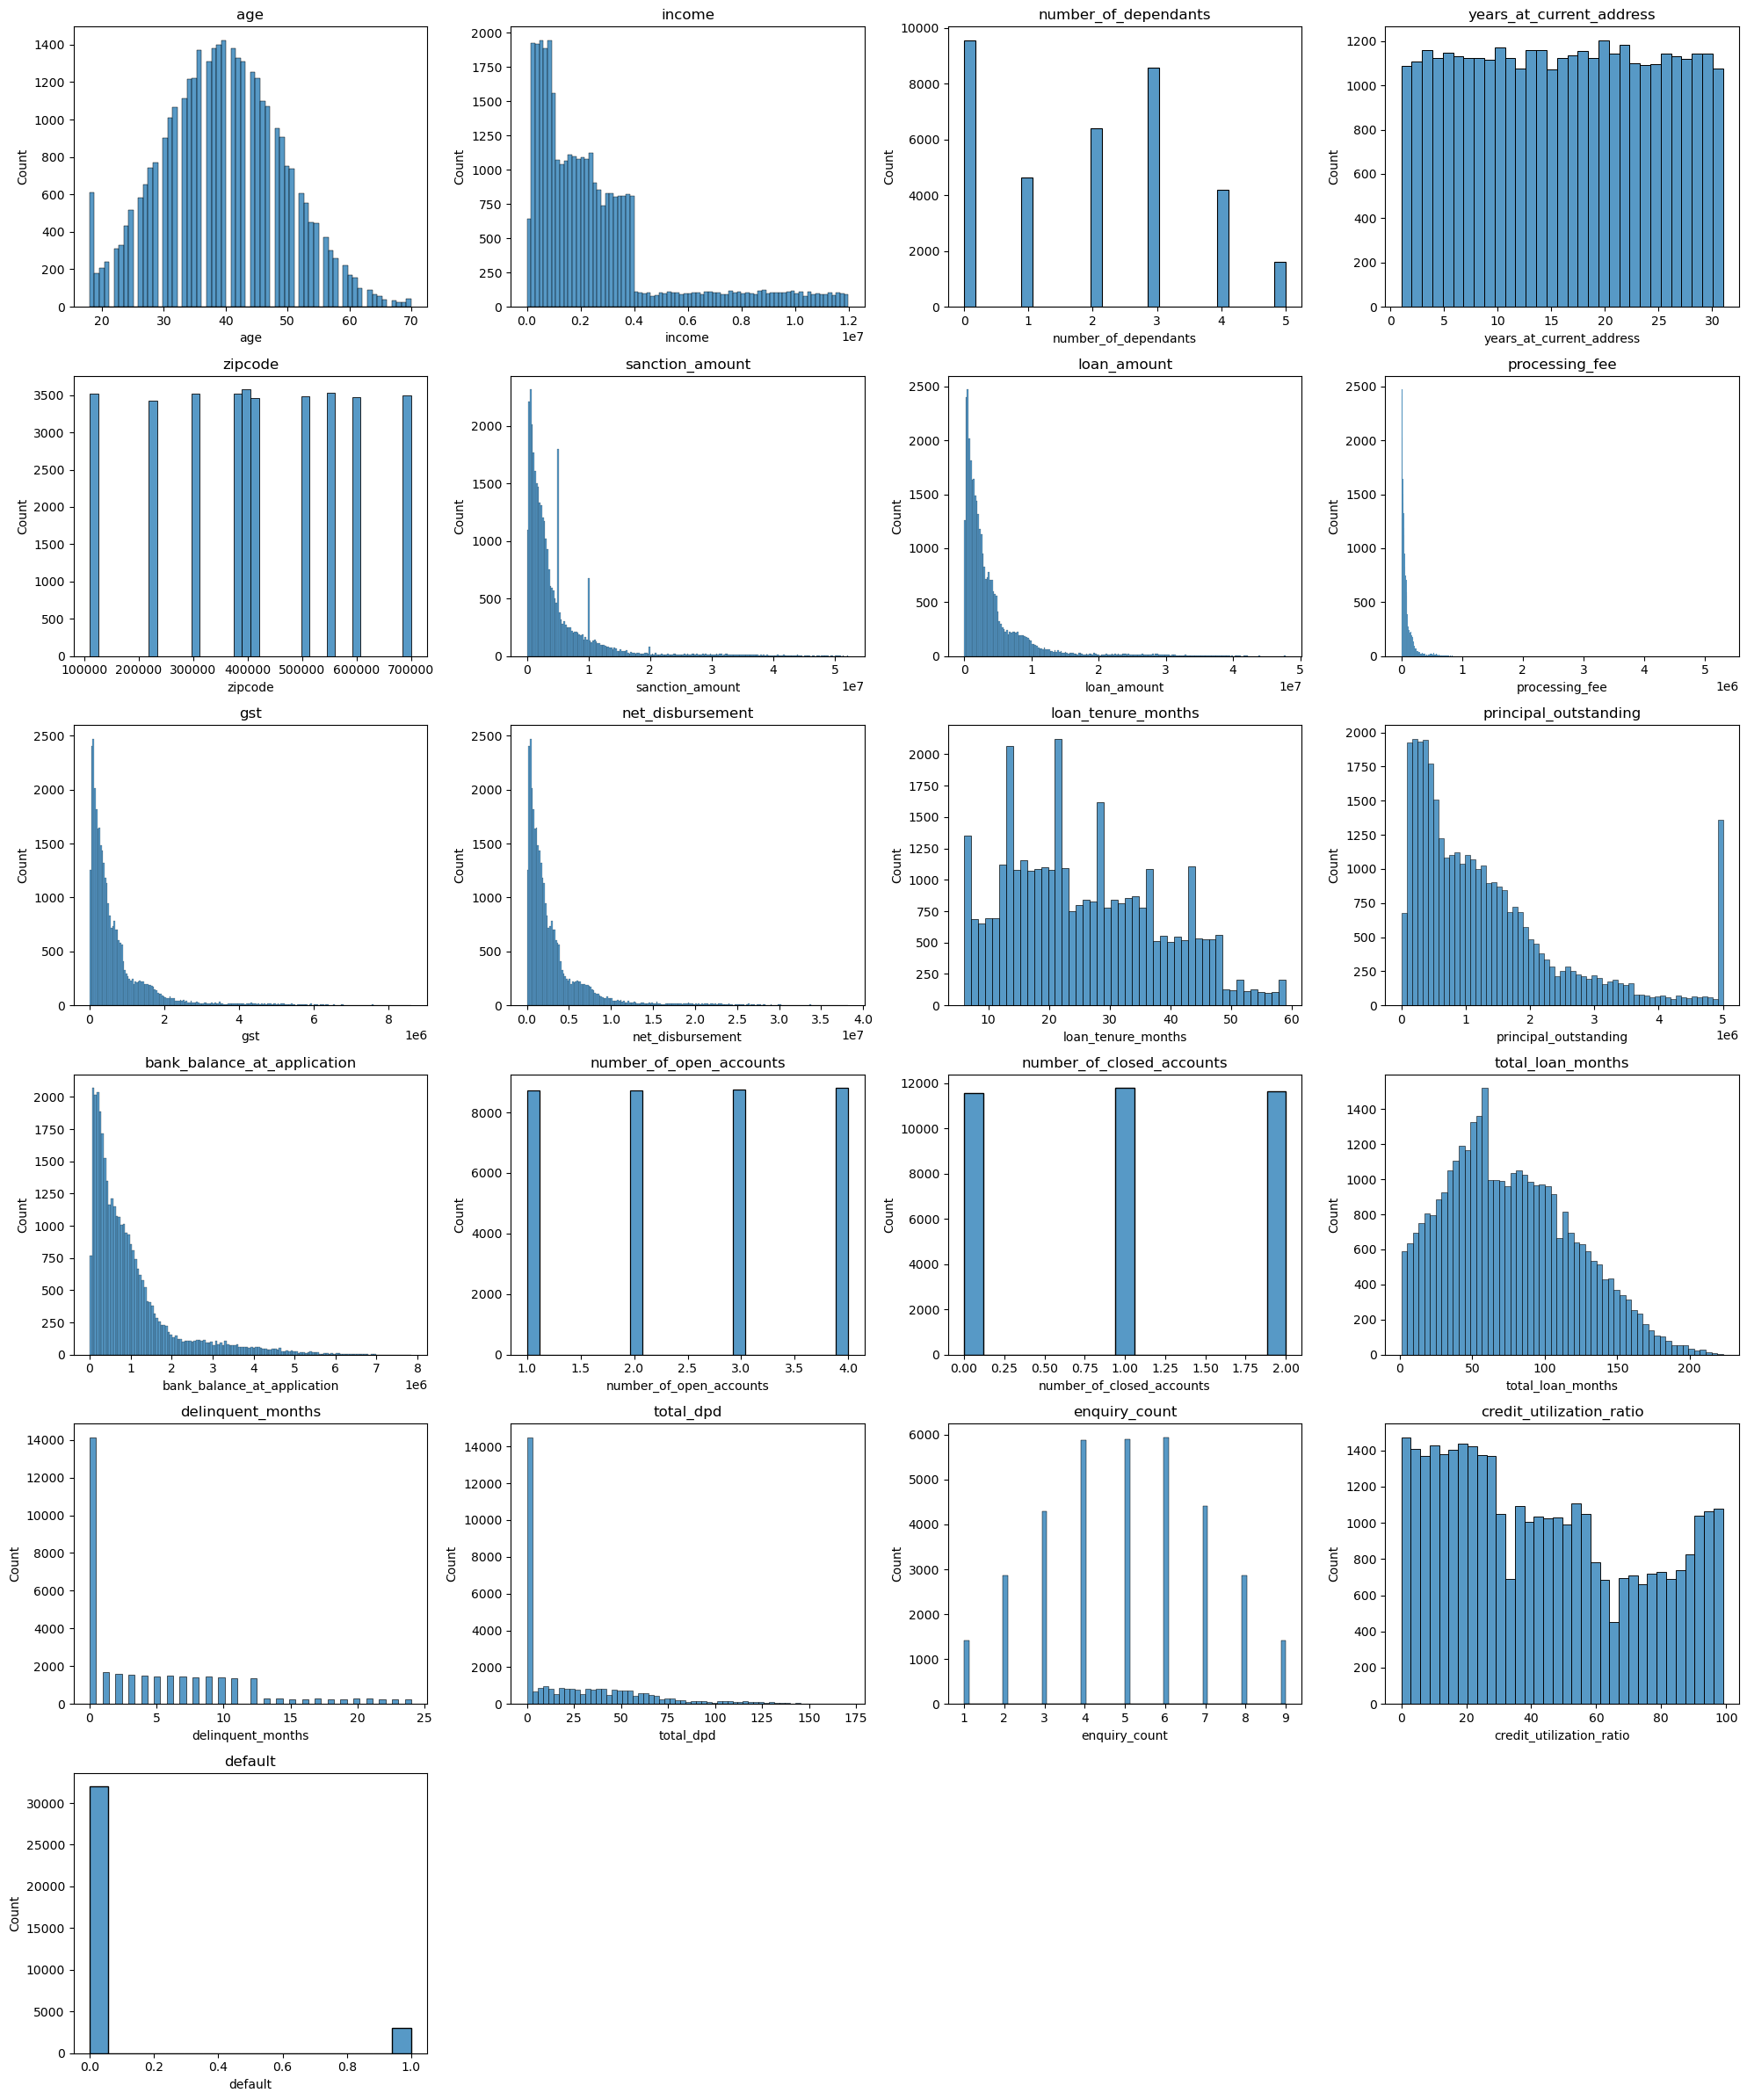

In [112]:
import pandas as pd 
from sklearn.model_selection import train_test_split
import seaborn as sns
from matplotlib import pyplot as plt 
import math


loans_df = pd.read_csv('loans.csv')
customers_df = pd.read_csv('customers.csv')
bureau_data_df = pd.read_csv('bureau_data.csv')


cust_loan_df = pd.merge(customers_df, loans_df, on = ['cust_id'])

df = pd.merge(cust_loan_df, bureau_data_df, on = ['cust_id'])
df['default'] = df['default'].map({True : 1, False :0})

# Due to data leakage problem in training traintestsplit is done first then apply all data cleaning and EDA on training columns and apply same for test columns separatelyabs
X = df.drop(columns=['default'], axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)


df_train = pd.concat([X_train, y_train], axis= 1)
df_test = pd.concat([X_test, y_test], axis = 1)

df_train['residence_type'] = df_train['residence_type'].fillna('Owned')
df_test['residence_type'] = df_test['residence_type'].fillna('Owned')

##EDA###

numerical_features = df_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df_train.select_dtypes(include=['object']).columns

#Outlier treatment for numerical columns
n_features = len(numerical_features)
n_cols = min(4, n_features)  # adjust as needed
n_rows = math.ceil(n_features / n_cols)

# Set figure size
plt.figure(figsize=(5 * n_cols, 4 * n_rows))

# Create subplots
for i, col in enumerate(numerical_features, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(x=df_train[col])
    plt.title(col)

plt.tight_layout()
plt.show()


# Set figure size
plt.figure(figsize=(5 * n_cols, 4 * n_rows))
for i, col in enumerate(numerical_features, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(x=df_train[col])
    plt.title(col)

plt.tight_layout()
plt.show()


In [113]:
# analyze processing fee outlier
df_train['processing_fee'].describe(

SyntaxError: incomplete input (1821968944.py, line 2)

In [ ]:
df_train = df_train[df_train['processing_fee'] < 0.3 * df_train['loan_amount']]
df_test = df_test[df_test['processing_fee'] < 0.3 * df_test['loan_amount']]

In [ ]:
df_train['loan_amount'].describe()

In [ ]:
df_train['gst'].max(), df_train['gst'].min() 

In [ ]:
df_train[df_train['gst'] > 0.2 * df_train['loan_amount']]

In [ ]:
categorical_features

In [ ]:
for col in categorical_features: 
    print(f'{col} : ', df_train[col].unique())

In [ ]:
df_train['loan_purpose'] = df_train['loan_purpose'].str.replace('Personaal', 'Personal')
df_test['loan_purpose'] = df_test['loan_purpose'].str.replace('Personaal', 'Personal')
df_train['loan_purpose'].unique()

In [ ]:
### EDA using kde plot

plt.figure(figsize= (8, 5))
sns.kdeplot(df_train['age'][df_train['default'] == 0], fill=True, label = 'default=0')
sns.kdeplot(df_train['age'][df_train['default'] == 1], fill=True, label = 'default=1')
plt.show()

In [ ]:
numercal_features

In [ ]:
n_features = len(numerical_features)
n_cols = min(4, n_features)  # You can set this to 2 for a 2-column layout
n_rows = math.ceil(n_features / n_cols)

# Set overall figure size
plt.figure(figsize=(5 * n_cols, 4 * n_rows))

# Create subplots
for i, col in enumerate(numerical_features, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.kdeplot(df_train[col][df_train['default'] == 0], fill=True, label = 'default=0')
    sns.kdeplot(df_train[col][df_train['default'] == 1], fill=True, label = 'default=1')
    plt.title(col)
    plt.xlabel('')
    plt.ylabel('Density')

plt.tight_layout()
plt.show()

In [ ]:
### 3 ration needs to be calculated 
#1. loan to income ration
#2. delin months to total loan months
#3. avg dpd per deliquency

df_train[['loan_amount', 'income']]

In [ ]:
df_train['loan_to_income'] = round(df_train['loan_amount'] / df_train['income'], 2)

df_test['loan_to_income'] = round(df_test['loan_amount'] / df_test['income'], 2)
df_train['loan_to_income']

In [ ]:
sns.kdeplot(df_train['loan_to_income'] [df_train['default'] == 0], fill=True, label='default=0')
sns.kdeplot(df_train['loan_to_income'] [df_train['default'] == 1], fill=True, label='default=1')

In [ ]:
## above graph says if ratio is more than 2 there is high chance of defaulter 
df_train['delinquent_ration'] = round(df_train['delinquent_months'] *100 / df_train['total_loan_months'], 1)
df_test['delinquent_ration'] = round(df_test['delinquent_months'] *100 / df_test['total_loan_months'], 1)

sns.kdeplot(df_train['delinquent_ration'][df_train['default'] == 0], fill= True, label = 'Default == 0')
sns.kdeplot(df_train['delinquent_ration'][df_train['default'] == 1], fill= True, label = 'Default == 1')

In [ ]:
import numpy as np
df_train['avg_dpd_per_delinquency'] = np.where(
    df_train['delinquent_months'] != 0,
    (df_train['total_dpd'] / df_train['delinquent_months']).round(1),
    0
)

df_test['avg_dpd_per_delinquency'] = np.where(
    df_test['delinquent_months'] != 0,
    (df_test['total_dpd'] / df_test['delinquent_months']).round(1),
    0
)

In [ ]:
df_train.sample(2)

In [ ]:
df_train1 = df_train.drop(columns= ['cust_id', 'loan_id'], axis= 1)
df_test = df_test.drop(columns= ['cust_id', 'loan_id'], axis= 1)


In [115]:
df_train2 = df_train1.drop(columns=['disbursal_date', 'installment_start_dt', 'loan_amount', 'income', 
                              'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)
df_test = df_test.drop(columns=['disbursal_date', 'installment_start_dt', 'loan_amount', 'income', 'total_loan_months', 'delinquent_months', 'total_dpd'], axis=1)


In [116]:
#do feature engineering for numercal features first
num_colums = df_train1.select_dtypes(include= ['int64', 'float64']).columns
num_colums

Index(['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'zipcode', 'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income', 'delinquent_ration', 'avg_dpd_per_delinquency'],
      dtype='object')